# SpaceX Falcon 9 First Stage Landing Prediction
Build, tune and compare four classifiers (Logistic Regression, SVM, Decision Tree, KNN) to predict `Class`.

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

In [2]:
p2 = 'dataset_part_2.csv' if os.path.exists('dataset_part_2.csv') else 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv'
p3 = 'dataset_part_3.csv' if os.path.exists('dataset_part_3.csv') else 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv'
data = pd.read_csv(p2)
X = pd.read_csv(p3)
Y = data['Class'].to_numpy()
print(X.shape, Y.shape)
X.head()

(90, 80) (90,)


,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6104.959412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Standardize and split (80% train / 20% test)

In [3]:
X = preprocessing.StandardScaler().fit_transform(X)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (72, 80)  Test: (18, 80)


## Plot helper

In [4]:
def plot_confusion_matrix(y, y_predict, title):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax, fmt='g')
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels'); ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land', 'landed']); ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

## Tune each model with GridSearchCV (cv = 10)

In [5]:
searches = {
    'Logistic Regression': GridSearchCV(LogisticRegression(max_iter=1000),
        {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}, cv=10),
    'SVM': GridSearchCV(SVC(),
        {'kernel': ['linear', 'rbf', 'poly', 'sigmoid'], 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}, cv=10),
    'Decision Tree': GridSearchCV(DecisionTreeClassifier(random_state=12345),
        {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'],
         'max_depth': [2 * n for n in range(1, 10)], 'max_features': ['sqrt', 'log2'],
         'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}, cv=10),
    'KNN': GridSearchCV(KNeighborsClassifier(),
        {'n_neighbors': list(range(1, 11)), 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}, cv=10),
}
for name, gs in searches.items():
    gs.fit(X_train, Y_train)
    print(f'{name}\n  best params: {gs.best_params_}\n  CV accuracy: {gs.best_score_:.4f}')

C:\Users\Connect2Aryans\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Connect2Aryans\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.

Logistic Regression
  best params: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
  CV accuracy: 0.8214
SVM
  best params: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
  CV accuracy: 0.8482
Decision Tree
  best params: {'criterion': 'gini', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'splitter': 'random'}
  CV accuracy: 0.8357
KNN
  best params: {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
  CV accuracy: 0.8339


## Test accuracy and confusion matrices

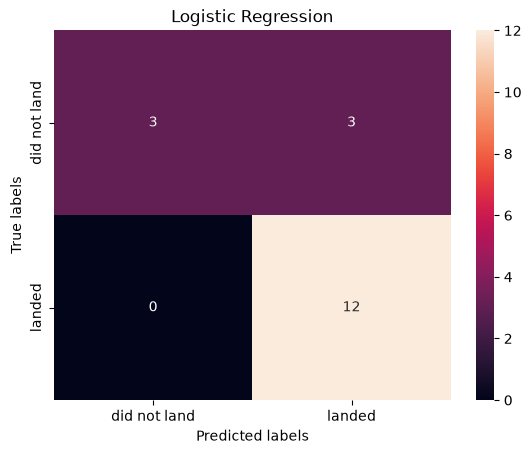

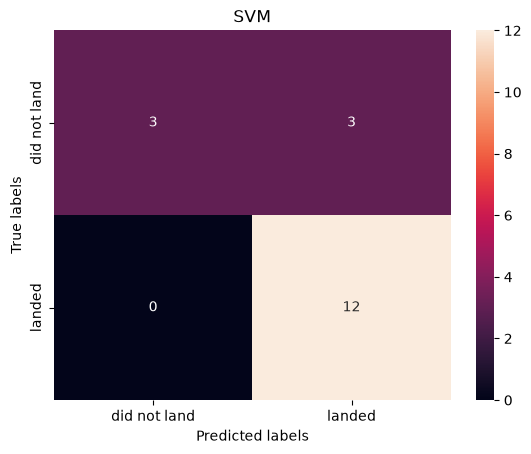

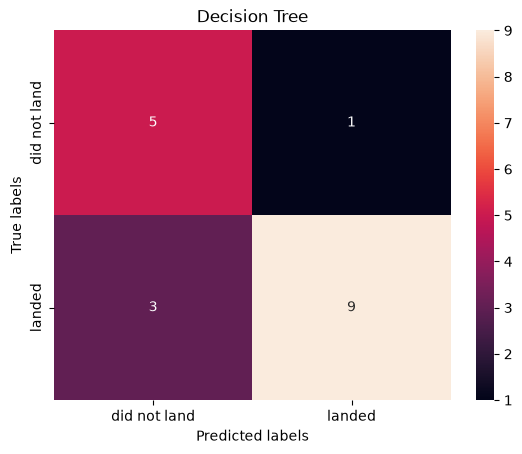

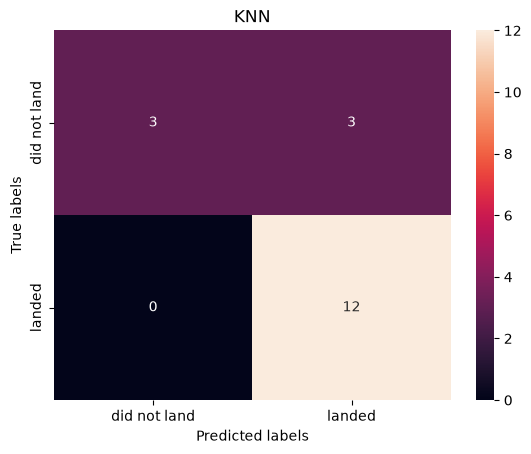

,Model,Test accuracy
0,Logistic Regression,0.833333
1,SVM,0.833333
2,Decision Tree,0.777778
3,KNN,0.833333


In [6]:
results = {}
for name, gs in searches.items():
    results[name] = gs.score(X_test, Y_test)
    plot_confusion_matrix(Y_test, gs.predict(X_test), name)
pd.DataFrame({'Model': list(results), 'Test accuracy': list(results.values())})

## Compare the models

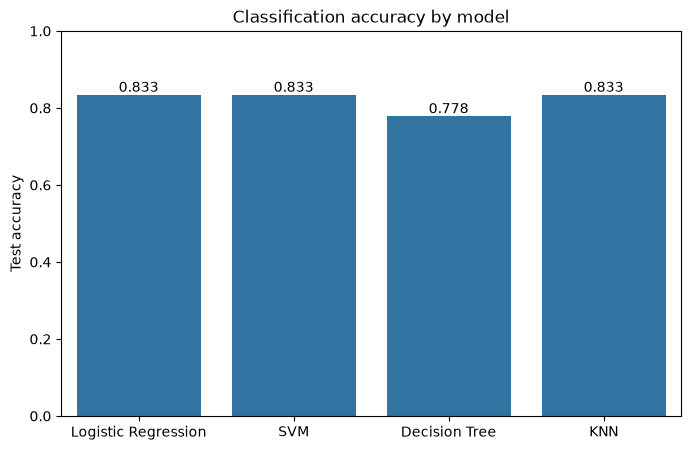

In [7]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=list(results.keys()), y=list(results.values()))
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.ylabel('Test accuracy'); plt.title('Classification accuracy by model'); plt.ylim(0, 1)
plt.show()   

Best model: Logistic Regression  test accuracy: 0.8333


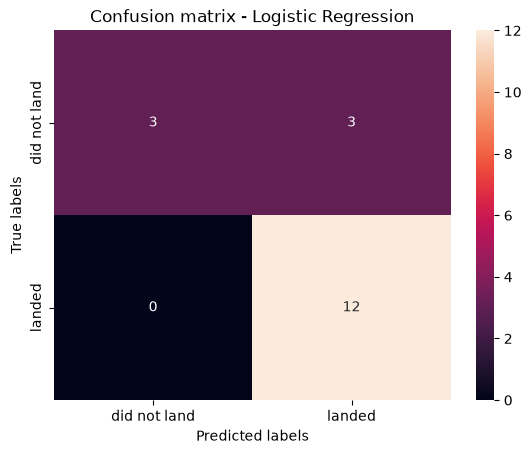

In [8]:
best = max(results, key=results.get)
print('Best model:', best, ' test accuracy:', round(results[best], 4))
plot_confusion_matrix(Y_test, searches[best].predict(X_test), 'Confusion matrix - ' + best)  